# Lab 01 — Color Fun
 
**Topics:** RGB channels, RGB→HSV conversion, color masks, selective recoloring, HSV visualization

## Learning outcomes

By the end of this lab, you should be able to:

1. interpret the three RGB channels;
2. convert a normalized RGB image to HSV and back;
3. build color masks in HSV;
4. recolor an object while retaining its shading and texture;
5. manipulate and visualize hue, saturation, and value;
6. explain why color thresholds can fail under shadows and highlights.

The supplied images are intentionally controlled. Thresholds that work here will not automatically generalize to every natural photograph.


**Name:** Quang Nguyen  
**Submission:** Lab 01 (Color Fun), completed and executed notebook

## 0. Setup — 5 minutes

Run the cell below to import the libraries, define two helper functions, load the sample images, and display them.

The images are stored as RGB NumPy arrays with floating-point values in **[0, 1]**. The printed output shows each image's shape, data type, and value range.

Check that both images load correctly and appear in the two-panel visualization before moving on.

### 💡 What this code does (simple explanation)

- **Imports** the tools: NumPy (arrays), Matplotlib (plots and the RGB↔HSV converters), PIL (opening image files).
- `load_rgb` opens a picture and divides by 255, so every pixel value is a decimal between **0 and 1** instead of 0–255. The HSV functions in Matplotlib expect this [0, 1] range.
- `show_grid` is just a helper to show several images next to each other with titles.
- The print line confirms each image is **height × width × 3** (3 = R, G, B), stored as `float32`, with min 0 and max 1.

**One-line version for the prof:** *"I load both images as float RGB in [0, 1] because Matplotlib's HSV conversion works on that range."*

Flower: (450, 800, 3) float32 0.0 1.0
Banana: (1086, 1448, 3) float32 0.0 1.0


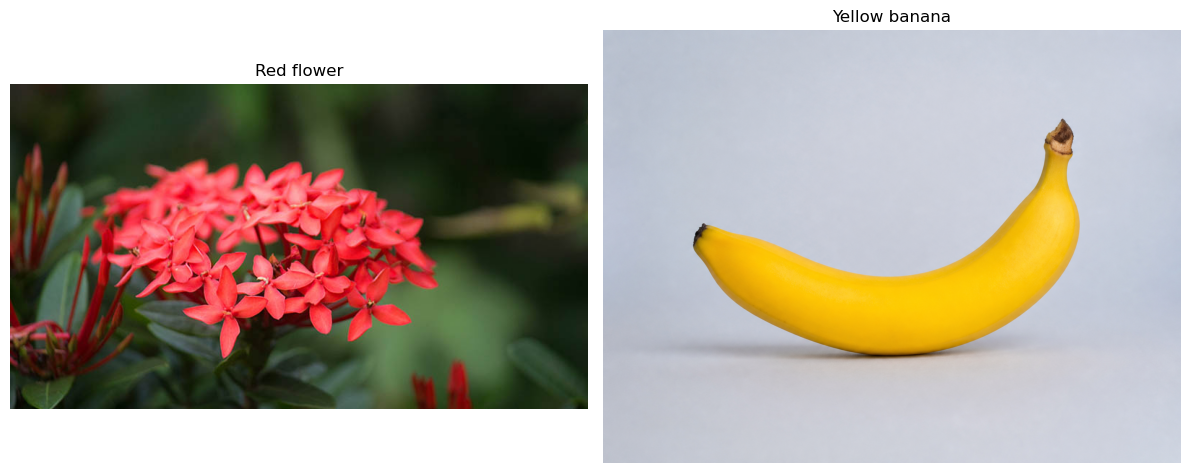

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import hsv_to_rgb, rgb_to_hsv
from PIL import Image

ASSETS = Path("images")

def load_rgb(path):
    """Load an image as float RGB in [0, 1]."""
    return np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0

def show_grid(images, titles, columns=3, figsize=(14, 8)):
    rows = int(np.ceil(len(images) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(np.clip(image, 0, 1))
        ax.set_title(title)
        ax.axis("off")
    for ax in axes[len(images):]:
        ax.axis("off")
    fig.tight_layout()
    return fig

flower = load_rgb(ASSETS / "jungle_flower.jpg")
banana = load_rgb(ASSETS / "yellow_banana.png")

print("Flower:", flower.shape, flower.dtype, flower.min(), flower.max())
print("Banana:", banana.shape, banana.dtype, banana.min(), banana.max())

show_grid([flower, banana], ["Red flower", "Yellow banana"], columns=2, figsize=(12, 5));


## 1. Explore the RGB channels — 8 minutes

### Question 1.1

Display the red, green, and blue contributions of the flower as color images. For the red contribution, keep the red channel and set the other two channels to zero. Repeat for green and blue.

### Question 1.2

Which channel contains the strongest response on the petals? Why are the leaves still visible in more than one channel?


### 💡 What this code does (simple explanation)

A colour image is really **three grey images stacked together**: one for red, one for green, one for blue.
To "see" just one channel as a colour, I keep that channel and put **zeros** (black) in the other two:

| Image | R | G | B |
|---|---|---|---|
| Red contribution | flower R | 0 | 0 |
| Green contribution | 0 | flower G | 0 |
| Blue contribution | 0 | 0 | flower B |

`np.dstack` glues the three layers back into an H×W×3 image. Bright areas in a panel = that colour is strong there.
The last few lines print the **average R, G, B on the petals and on the leaves** so my answer has numbers, not just eyeballing.

Mean [R, G, B] on petals: [0.823 0.246 0.268]
Mean [R, G, B] on leaves: [0.169 0.226 0.13 ]


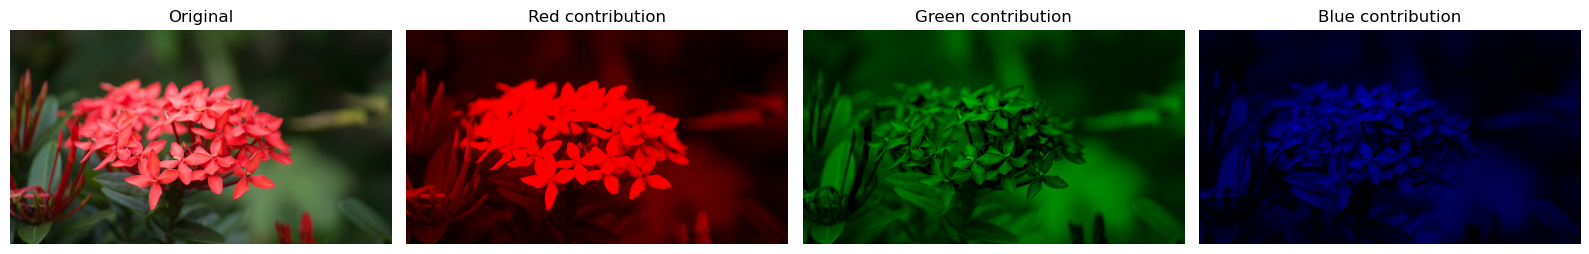

In [2]:
# Make three H×W×3 images, each one keeping only ONE colour channel.
zeros = np.zeros_like(flower[..., 0])   # a black H×W layer (all 0)

red_contribution   = np.dstack([flower[..., 0], zeros, zeros])   # keep R, set G=B=0
green_contribution = np.dstack([zeros, flower[..., 1], zeros])   # keep G, set R=B=0
blue_contribution  = np.dstack([zeros, zeros, flower[..., 2]])   # keep B, set R=G=0

# show the original image and the three contributions in a 1×4 grid.
show_grid(
    [flower, red_contribution, green_contribution, blue_contribution],
    ["Original", "Red contribution", "Green contribution", "Blue contribution"],
    columns=4,
    figsize=(16, 4),
);

# Numbers to back up the answer: average R, G, B on the petals vs on the leaves.
_hsv = rgb_to_hsv(flower)
_petals = ((_hsv[..., 0] < 0.045) | (_hsv[..., 0] > 0.955)) & (_hsv[..., 1] > 0.45) & (_hsv[..., 2] > 0.25)
_leaves = (_hsv[..., 0] > 0.15) & (_hsv[..., 0] < 0.5) & (_hsv[..., 1] > 0.2)
print("Mean [R, G, B] on petals:", np.round(flower[_petals].mean(axis=0), 3))
print("Mean [R, G, B] on leaves:", np.round(flower[_leaves].mean(axis=0), 3))

#### Answer 1.2

**Your answer:**

- **The red channel has the strongest response on the petals.** In the "Red contribution" panel the petals are bright, but in the green and blue panels they are almost black. The numbers agree: on the petals the mean [R, G, B] ≈ **[0.82, 0.25, 0.27]**, so R is more than 3× larger than G or B.
- **The leaves appear in more than one channel** because real colours are a **mix** of R, G and B, not one pure channel. A dark natural green leaf is roughly **[0.17, 0.23, 0.13]**: G is the largest, but R and B are far from zero. Leaves also reflect some light of every wavelength and have bright shiny highlights (which are near-white, so high in all three). The camera's R, G and B filters also overlap, so one surface gives a signal in several channels.
- **In short:** a channel shows *how much* of that primary is in a pixel, not *whether the object is that colour*. That is why RGB alone is awkward for selecting "the red thing", and why we move to HSV next.

## 2. Recolor the red flower — 15 minutes

We will detect the red petals in HSV and replace only their hue. Saturation and value are preserved so the flower keeps its texture, highlights, and shadows.

### Question 2.1

Convert the flower to HSV and create a red-petal mask using:

- H < 0.045 **or** H > 0.955;
- S > 0.45;
- V > 0.25.

Why does red require an **OR** condition?

### Question 2.2

Write a function that replaces hue inside a mask. Recolor the flower to:

- green: H = 1/3;
- blue: H = 2/3.


### 💡 What this code does (simple explanation)

1. **Convert to HSV.** HSV splits colour into 3 easy ideas:
   - **H (hue)** = *which* colour (red, yellow, green…), as a position on a colour **circle** from 0 to 1;
   - **S (saturation)** = how *strong/pure* the colour is (0 = grey, 1 = vivid);
   - **V (value)** = how *bright* it is (0 = black, 1 = brightest).
2. **Build the mask**, a True/False picture where True means "this pixel is red petal" (shown as **yellow** in the plot, False as **purple**):
   - hue near 0 **or** near 1 → red;
   - **and** S > 0.45 → really colourful, not greyish;
   - **and** V > 0.25 → not in deep shadow.
3. **Recolour.** `recolor_hue` changes **only H** inside the mask and leaves S and V untouched. Then it converts back to RGB.
   Setting H = 1/3 gives green, and H = 2/3 gives blue.

Because S and V are kept, the petals keep their **shading, highlights and texture**. Only the "name" of the colour changes.

Red mask selects 23.3% of the pixels
  from the low end  (H < 0.045): 7.5%
  from the high end (H > 0.955): 15.7%


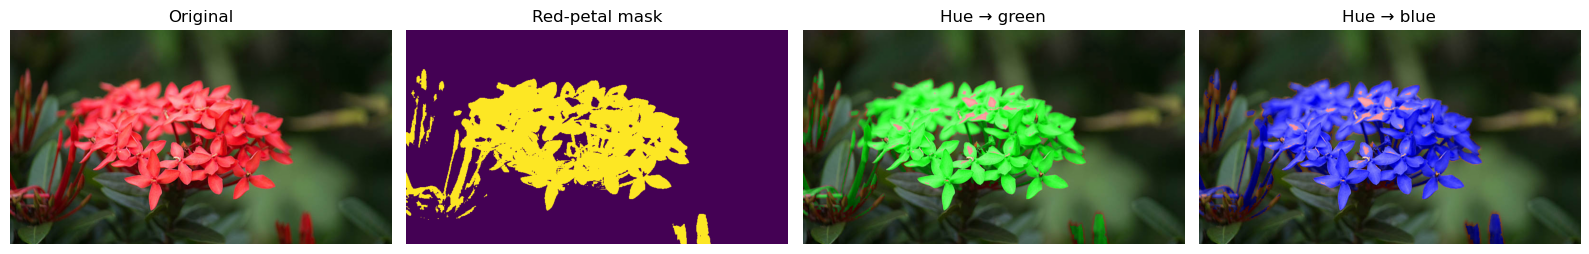

In [3]:
flower_hsv = rgb_to_hsv(flower)            # RGB -> HSV, every value in [0, 1]
h, s, v = np.moveaxis(flower_hsv, -1, 0)   # split into three H×W arrays

# Red sits at BOTH ends of the hue circle (near 0 and near 1), so we need OR for hue,
# then AND with "colourful enough" (S) and "bright enough" (V).
red_mask = ((h < 0.045) | (h > 0.955)) & (s > 0.45) & (v > 0.25)

def recolor_hue(rgb, mask, target_hue):
    """Replace hue inside mask while preserving saturation and value."""
    hsv = rgb_to_hsv(rgb)
    edited_hsv = hsv.copy()
    edited_hsv[..., 0][mask] = target_hue % 1.0
    return hsv_to_rgb(edited_hsv)

flower_green = recolor_hue(flower, red_mask, 1/3)   # H = 1/3 -> green
flower_blue  = recolor_hue(flower, red_mask, 2/3)   # H = 2/3 -> blue

print(f"Red mask selects {red_mask.mean():.1%} of the pixels")
print(f"  from the low end  (H < 0.045): {((h < 0.045) & red_mask).mean():.1%}")
print(f"  from the high end (H > 0.955): {((h > 0.955) & red_mask).mean():.1%}")

# original, mask, green result, blue result.
show_grid(
    [flower, red_mask, flower_green, flower_blue],
    ["Original", "Red-petal mask", "Hue → green", "Hue → blue"],
    columns=4,
    figsize=(16, 4),
);

#### Answer 2.1: why red needs an OR

**Your answer:**

- Hue is an **angle on a circle**, scaled to [0, 1). Red sits exactly where the circle **joins**: H = 0 and H = 1 are the *same* colour.
- So red pixels split into two groups: slightly orange-red ones just **above 0** (H < 0.045), and slightly pink/magenta-red ones just **below 1** (H > 0.955).
- A single range `0.955 < H < 0.045` is impossible (there is no number that is both > 0.955 and < 0.045), so we must write **`(H < 0.045) OR (H > 0.955)`**.
- The run shows both halves really are used. The mask selects about **23 %** of the image: about **7.5 %** comes from the low end and **15.7 %** from the high end. Using only one side would miss most of the petals.
- The S and V conditions are joined with **AND** so the mask keeps only pixels that are red **and** colourful **and** not too dark. This removes dark shadow pixels and greyish pixels whose hue is unreliable.

#### Answer 2.2: recolouring

**Your answer:**

- `recolor_hue` converts to HSV, sets **H = target** only where `mask` is True, and converts back. **S and V are not touched.**
- **H = 1/3 → green flower, H = 2/3 → blue flower.** In both results the petals keep their folds, darker edges and highlights, because brightness (V) and colour strength (S) are the same as the original. Only *which* colour changed.
- The leaves, stems and background are unchanged because they are outside the mask.
- **Limitations I can see in the result:**
  - The **pale pink centres** of some flowers stay **pink**. They are less saturated (S < 0.45), so the mask leaves them out.
  - The mask also picks up the **red stems and flower buds** on the left and bottom of the picture, so they turn green/blue too. The rule selects *anything* red, not just petals.
  - The mask edge is **jagged** because a hard threshold makes a yes/no decision for each pixel (see exit question 4).

## 3. Recolor the yellow banana — 10 minutes

### Question 3.1

Build a yellow-peel mask using:

- 0.08 < H < 0.19;
- S > 0.25;
- V > 0.30.

Recolor the peel to red (H = 0) and green (H = 1/3).

### Question 3.2

Inspect the banana tips, edge pixels, and shadow. Which areas are excluded by the mask, and which threshold is mainly responsible?


### 💡 What this code does (simple explanation)

Same idea as the flower, but for the banana:

- **Yellow** lives in one continuous range of hue (0.08–0.19). Unlike red, it does **not** wrap around the 0/1 point, so only **AND** conditions are needed.
- S > 0.25 removes the greyish background; V > 0.30 removes very dark pixels.
- Then I reuse the **same** `recolor_hue` function: H = 0 → red banana, H = 1/3 → green banana.

In the mask panel, **yellow = True** (the pixel gets recoloured) and **purple = False** (the pixel stays exactly as in the original). Matplotlib draws a True/False picture with its default yellow/purple colours.

Yellow mask selects 13.1% of the pixels


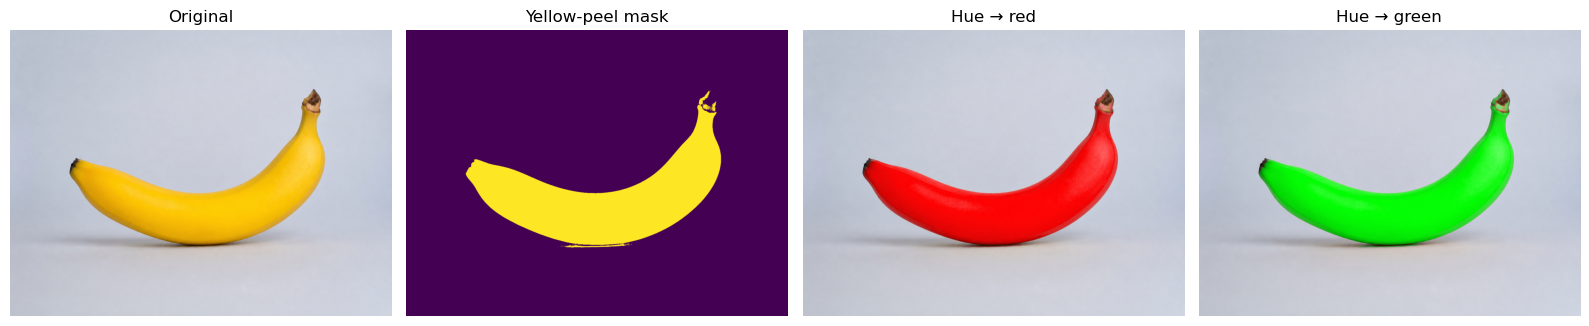

In [4]:
banana_hsv = rgb_to_hsv(banana)
h, s, v = np.moveaxis(banana_hsv, -1, 0)

# Yellow is one continuous band of hue (no wrap-around), so only AND is needed.
yellow_mask = (h > 0.08) & (h < 0.19) & (s > 0.25) & (v > 0.30)

banana_red   = recolor_hue(banana, yellow_mask, 0.0)   # H = 0   -> red
banana_green = recolor_hue(banana, yellow_mask, 1/3)   # H = 1/3 -> green

print(f"Yellow mask selects {yellow_mask.mean():.1%} of the pixels")

# display original, mask, and both results.
show_grid(
    [banana, yellow_mask, banana_red, banana_green],
    ["Original", "Yellow-peel mask", "Hue → red", "Hue → green"],
    columns=4,
    figsize=(16, 4),
);

#### Answer 3.2: what the yellow mask misses

**Your answer:**

The yellow mask covers about **13 %** of the image, which is almost the whole banana peel. The pixels it **excludes** are:

1. **The two tips (the stem and the dark end).** They are **brown/black**, not yellow. Brown is really a *dark orange*, with hue **below 0.08**, and the black end is also very dark. **Main threshold: the hue lower bound H > 0.08**, helped by **V > 0.30** on the darkest bits. In my check, almost all excluded banana pixels fail the hue test.
2. **Edge pixels around the outline.** These pixels are a **blend** of yellow peel and the grey-blue background. The blend lowers saturation and pulls the hue away from yellow, so they fail **S > 0.25** (and sometimes the hue range). This gives a slightly jagged outline.
3. **The shadow on the table under the banana.** It is grey with very low saturation, so it is excluded by **S > 0.25**. *This is correct:* the shadow is not peel, so it should not be recoloured. (Its hue is meaningless red/magenta noise; see Q4.3.)
4. **The darker underside of the peel**, where it meets the shadow. The colour there turns dark orange (H ≈ 0.09, just above the 0.08 cut-off), so it is **borderline**: most of it is kept, but the bottom edge of the mask is ragged where pixels fall on either side of H = 0.08 / V = 0.30.

**Summary:** the tips are lost mainly because of the **hue lower bound (0.08)** and **V**; the edges and the floor shadow are lost mainly because of the **saturation threshold (0.25)**.

## 4. Convert RGB to HSV and visualize it — 10 minutes

### Question 4.1

Visualize the flower and banana as four panels:

1. RGB image;
2. H with the **hsv** colormap and limits [0,1];
3. S in grayscale with limits [0,1];
4. V in grayscale with limits [0,1].

### Question 4.2

Convert HSV back to RGB and report the maximum absolute round-trip error.

### Question 4.3

Why is hue visually noisy or arbitrary in low-saturation background regions?


### 💡 What this code does (simple explanation)

**Part 1: Visualise HSV.** For each image I show four panels:
- the normal RGB photo;
- **H** drawn with the rainbow `hsv` colormap, so each colour shows up as its own colour;
- **S** and **V** in **grayscale** (white = high, black = low). All are fixed to [0, 1] so the panels can be compared.

**Part 2: Round trip.** I convert RGB → HSV → back to RGB and subtract the original.
`np.abs(...).max()` gives the **single biggest difference** over every pixel and channel.
If it is tiny (much smaller than one 8-bit step, 1/255 ≈ 0.004), the conversion is **lossless in practice**.

Maximum round-trip error: 4.023e-07
(One 8-bit grey level is 1/255 = 3.922e-03)


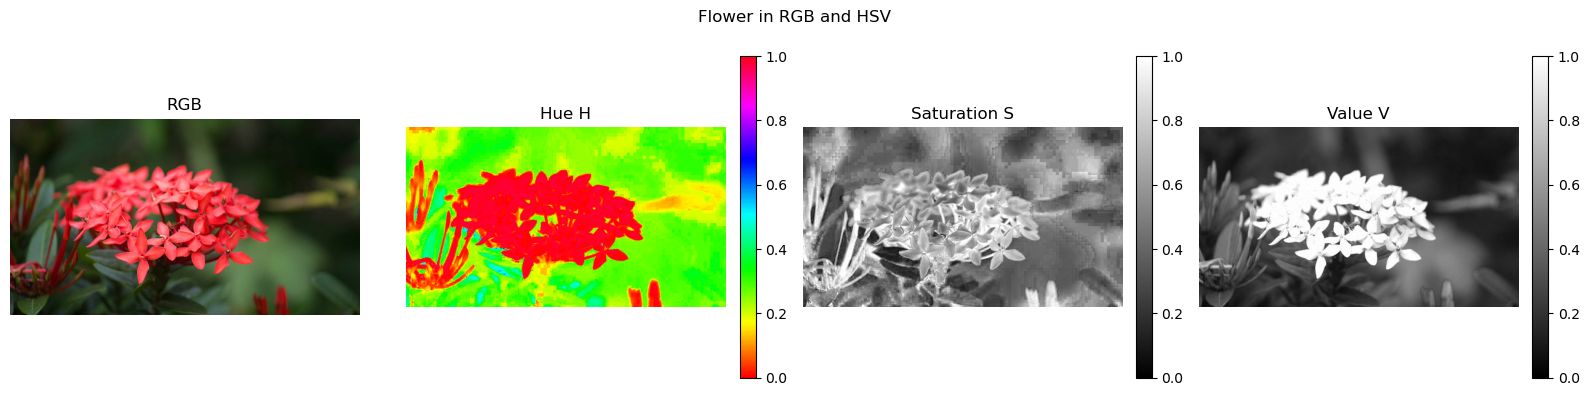

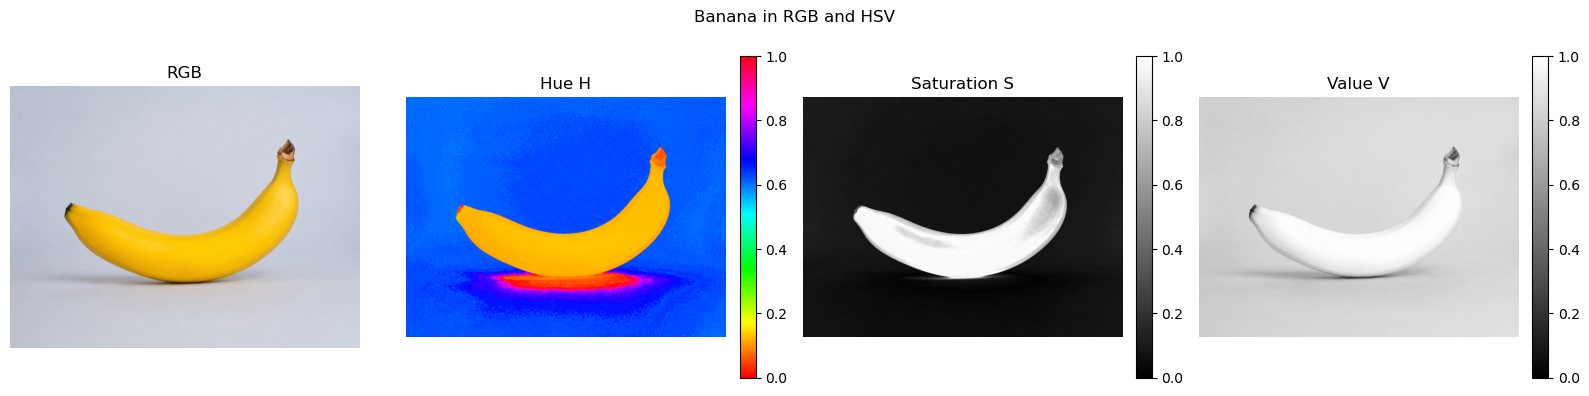

In [5]:
def plot_hsv_channels(rgb, title):
    hsv = rgb_to_hsv(rgb)   # convert once, then show H, S, V side by side
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(rgb)
    axes[0].set_title("RGB")
    axes[0].axis("off")
    for ax, channel, name, cmap in zip(
        axes[1:],
        [hsv[..., 0], hsv[..., 1], hsv[..., 2]],
        ["Hue H", "Saturation S", "Value V"],
        ["hsv", "gray", "gray"],
    ):
        im = ax.imshow(channel, cmap=cmap, vmin=0, vmax=1)
        ax.set_title(name)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.suptitle(title)
    fig.tight_layout()
    return fig

plot_hsv_channels(flower, "Flower in RGB and HSV");
plot_hsv_channels(banana, "Banana in RGB and HSV");

# RGB -> HSV -> RGB, then measure the biggest difference from the original.
flower_round_trip = hsv_to_rgb(rgb_to_hsv(flower))
error_map = np.abs(flower_round_trip - flower)   # per-pixel, per-channel error
max_error = error_map.max()
print(f"Maximum round-trip error: {max_error:.3e}")
print(f"(One 8-bit grey level is 1/255 = {1/255:.3e})")

#### Answer 4.2: round-trip error

**Your answer:**

- RGB → HSV → RGB gives a **maximum absolute error of about 4 × 10⁻⁷** (see the printed value above).
- That is about **10,000× smaller than one 8-bit grey level** (1/255 ≈ 3.9 × 10⁻³), so it is invisible and the images are the same in practice.
- The error is not exactly 0 because the computer stores numbers as **float32** with limited precision. The conversion involves divisions and max/min operations, which add tiny rounding errors.
- **Conclusion:** HSV is an **exact, reversible re-arrangement** of the same information (no information is lost), so we can edit in HSV and safely convert back.

#### Answer 4.3: why hue is noisy in grey regions

**Your answer:**

- Hue answers *"which colour?"*. In a **grey or white** pixel, R ≈ G ≈ B, so **there is no colour to name**. Saturation is near 0.
- Mathematically, hue is computed from the **differences** between R, G and B, divided by (max − min). When max − min is tiny, a difference of 1–2 levels caused by **sensor noise or JPEG compression** completely changes the hue. When max = min, hue is undefined and Matplotlib just sets it to 0 (red).
- You can see this clearly in the **banana H panel**. The grey background (S ≈ **0.07**) shows a speckled blue, and the **grey shadow under the banana shows up as a bright red/magenta patch**, even though nothing there is red. A tiny warm tint plus noise is enough to send the hue to the other side of the circle.
- In the **flower** S panel you can even see **8×8 JPEG blocks** in the dark background. When colours are dark and dull, compression errors are large relative to the real colour, so H and S become blocky and unreliable.
- **Practical rule:** only trust H where **S (and V) are high enough**. That is exactly why every mask in this lab also has `S > …` and `V > …` conditions.

## 5. HSV playground — 10 minutes

Create and compare the following global edits:

1. rotate hue by +0.20 using modulo 1;
2. reduce saturation to 25%;
3. increase saturation by 1.40 and clip to [0,1];
4. reduce value to 55%;
5. increase value by 1.25 and clip to [0,1].

### Question 5.1

Which operation changes perceived color family without directly changing the stored V channel?

### Question 5.2

Why must hue rotation use modulo 1? Why must scaled S and V values be clipped?


### 💡 What this code does (simple explanation)

Five **global** edits, meaning they apply to the whole image and not just a mask. Each starts from a fresh `.copy()` of the HSV image:

| Edit | Code idea | What you see |
|---|---|---|
| Hue + 0.20 | `(H + 0.2) % 1` | every colour moves 0.2 around the colour circle (red petals → yellow, green leaves → teal) |
| S × 0.25 | multiply S | colours become washed-out, almost grey |
| S × 1.40 | multiply S, **clip** to [0,1] | colours become more vivid |
| V × 0.55 | multiply V | whole image darker |
| V × 1.25 | multiply V, **clip** to [0,1] | whole image brighter; bright parts saturate to max |

- `% 1.0` (modulo) **wraps** hue around the circle, so 1.1 becomes 0.1.
- `np.clip` stops values from going above 1, which is not a valid HSV value.

Then `hsv_to_rgb` turns every edited version back into a normal picture.

Pixels with S×1.40 > 1: 18.1%
Pixels with V×1.25 > 1: 16.6%


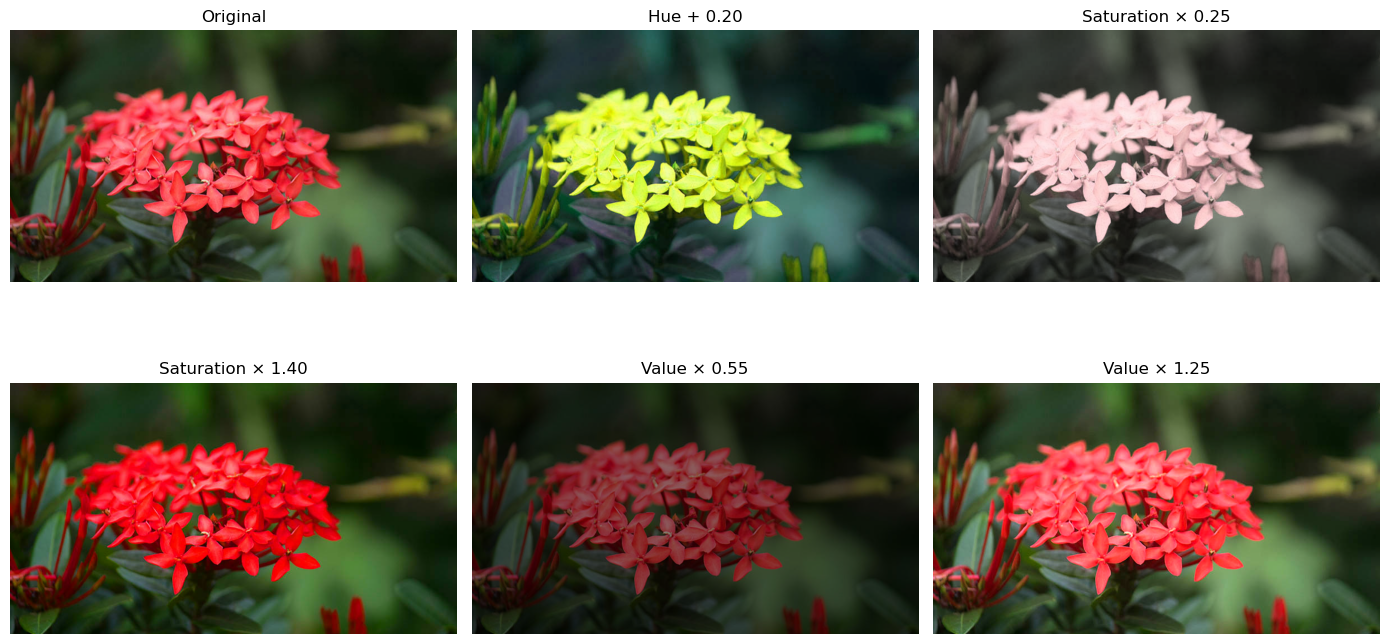

In [6]:
hsv = rgb_to_hsv(flower)

# Each edit works on its own copy so the edits do not stack on top of each other.
hue_shifted = hsv.copy()
hue_shifted[..., 0] = (hsv[..., 0] + 0.20) % 1.0          # rotate hue, wrap around the circle

low_saturation = hsv.copy()
low_saturation[..., 1] *= 0.25                            # 25% of the original saturation

high_saturation = hsv.copy()
high_saturation[..., 1] = np.clip(hsv[..., 1] * 1.40, 0, 1)   # ×1.40, then keep inside [0, 1]

darker = hsv.copy()
darker[..., 2] *= 0.55                                    # 55% of the original brightness

brighter = hsv.copy()
brighter[..., 2] = np.clip(hsv[..., 2] * 1.25, 0, 1)      # ×1.25, then keep inside [0, 1]

show_grid(
    [
        flower,
        hsv_to_rgb(hue_shifted),
        hsv_to_rgb(low_saturation),
        hsv_to_rgb(high_saturation),
        hsv_to_rgb(darker),
        hsv_to_rgb(brighter),
    ],
    [
        "Original",
        "Hue + 0.20",
        "Saturation × 0.25",
        "Saturation × 1.40",
        "Value × 0.55",
        "Value × 1.25",
    ],
    columns=3,
    figsize=(14, 8),
);

# How many pixels would go past 1 without clipping?
print(f"Pixels with S×1.40 > 1: {(hsv[..., 1] * 1.40 > 1).mean():.1%}")
print(f"Pixels with V×1.25 > 1: {(hsv[..., 2] * 1.25 > 1).mean():.1%}")

#### Answer 5.1

**Your answer:**

- **Hue rotation (H + 0.20)** changes the perceived colour family. The red petals turn **yellow** (H ≈ 0 → 0.2) and the green leaves turn **teal/cyan** (H ≈ 0.3 → 0.5), yet **the stored V channel is not touched at all** (only `[..., 0]` is edited).
- The saturation edits also leave V unchanged, but they only make colours **duller or stronger**. Red stays red. Only the hue edit moves colours into a **different family**.
- *(Note: even though V is unchanged, the image can look a bit brighter or darker after a hue shift. This is because our eyes see yellow as brighter than blue at the same V, a sign that HSV is not perceptually uniform.)*

#### Answer 5.2

**Your answer:**

- **Modulo 1 for hue:** hue is a **circle**, so after 1 it should come back to 0, the way 370° = 10°. A red pixel at H = 0.9 plus 0.2 gives 1.1, which is outside the valid range. `1.1 % 1 = 0.1` puts it in the correct place (orange/yellow) on the circle. Clipping would be **wrong** here: it would squash every such pixel to 1.0 (red) instead of rotating it.
- **Clip for S and V:** S and V are **amounts**, not angles. They have a hard range of [0, 1]: you cannot be more than 100 % pure or brighter than white. ×1.40 and ×1.25 push many pixels above 1 (see the printed percentages). Without clipping, `hsv_to_rgb` would produce RGB values > 1, which are invalid and display incorrectly. Clipping sets them to the maximum instead.
- Side effect: clipped pixels all become exactly 1, so **detail in the brightest or most saturated areas is lost** (they "burn out").

## 6. Exit questions — 5 minutes

1. Why is HSV often convenient for interactive color selection and simple thresholding?
2. Why is HSV not a perceptually uniform space?
3. What problems would appear if the flower were illuminated by strongly colored light?
4. How would you improve jagged mask boundaries?
5. When changing only H, what image properties are intentionally preserved?


#### Exit question answers

**Your answer:**

1. **Why HSV is convenient for selection/thresholding:** it separates *what colour* (H) from *how strong* (S) and *how bright* (V). "Red petals" become one simple rule on H, plus "colourful enough" (S) and "not too dark" (V). In RGB, a red petal in shadow and in sunlight have very different R, G, B numbers, but in HSV their **hue stays almost the same** and only V changes. That makes thresholds simple and intuitive to tune by hand.

2. **Why HSV is not perceptually uniform:** HSV is just a **geometric re-arrangement of RGB**. It was not built from measurements of human vision. Equal steps in H, S or V do **not** look like equal changes to our eyes. For example, at the same V = 1, pure **yellow looks much brighter than pure blue**, and a 0.05 hue step in the greens looks smaller than the same step around orange or red. Perceptual spaces such as **CIELAB** are designed so that equal distances ≈ equal visible differences.

3. **Strongly coloured light:** HSV measures the colour **reaching the camera** (object colour × light colour), not the object's true colour. Under, say, strong blue light the red petals would look purple or dark (hue shifts and V drops), so the fixed thresholds would **miss them**. Meanwhile white or green parts could pick up a reddish tint and be **wrongly selected**. Shadows and highlights would also behave differently. Fixes include **white balancing / colour constancy** before thresholding, or adapting the thresholds to each image.

4. **Improving jagged mask boundaries:**
   - **Morphology:** an *opening* removes isolated specks and a *closing* fills small holes and gaps (`scipy.ndimage` / OpenCV).
   - **Smooth before thresholding** (a small Gaussian blur on the image or on H/S), so single noisy pixels do not flip.
   - **Soft (feathered) mask:** blur the mask into values between 0 and 1 and **blend** the original and recoloured images, so edges fade smoothly instead of stepping.
   - Keep only the **largest connected components**, or use smarter segmentation (GrabCut, a learned model) for real photos.

5. **What is preserved when only H changes:** **saturation and value**, which means the object's **shading, shadows, highlights, texture and fine detail**, plus its shape and position. The colour intensity (how vivid it is) also stays the same. Everything outside the mask stays **identical** to the original. That is why the recoloured flower and banana still look like real 3-D objects instead of flat paint.

## Optional extension

Try your own photograph. First plot its HSV channels, then choose thresholds interactively. Report:

- your final H/S/V bounds;
- the fraction of pixels selected;
- one failure case;
- one proposed improvement.

**Caution:** OpenCV commonly stores HSV hue in [0,179] for 8-bit images, while Matplotlib uses [0,1). Do not mix thresholds between conventions.


*(Optional: not attempted.)*